In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [2]:
import seaborn as sns

In [3]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    #eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]

    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")

def plot_distributions(scores, labels, lbound=None, hbound=None, thr=0, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)
        #print(f"Loaded {len(scores)} samples")
        #print(f"Real mean score: {real_scores.mean():.4f}")
        #print(f"Fake mean score: {fake_scores.mean():.4f}\n")
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    #sns.histplot(real_scores, bins=50, stat="count", kde=False, color='blue', alpha=0.4, label="Real (0)", ax=ax)
    #sns.histplot(fake_scores, bins=50, stat="count", kde=False, color='orange', alpha=0.4, label="Fake (1)", ax=ax)

    ax.axvline(thr, linestyle="--", linewidth=2, color="red")
    
    if lbound is not None:
        ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
        
    ax.legend()


def plot_raw_scatter(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    real_y = np.zeros_like(real_scores)
    fake_y = np.ones_like(fake_scores)

    ax.scatter(real_scores, real_y, alpha=0.5, label="Real (0)")
    ax.scatter(fake_scores, fake_y, alpha=0.5, label="Fake (1)")
    ax.set_xlabel("Score")
    ax.set_ylabel("Label")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real", "Fake"])
    ax.legend()


def print_expert_stats(name, idx, raw, scaled):
    print(f"{name} (idx={idx})")
    print("-" * 40)

    print("Raw logits")
    print(f"  std: {np.std(raw[idx]):.4f}")
    print(f"  min/max: {raw[idx].min():.4f} / {raw[idx].max():.4f}")

    print("\nScaled logits")
    print(f"  std: {np.std(scaled[idx]):.6f}")
    print(f"  min/max: {scaled[idx].min():.6f} / {scaled[idx].max():.6f}")

    print()


def plot_platt(a, b, logits, ax=None, title=""):
    if ax is None:
        ax = plt.gca()

    # Full sigmoid
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))

    # Data range
    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))

    # Min/max points
    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))

    # Plot on given axis
    ax.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    ax.plot(z_data, p_data, linewidth=3, label="Used region")
    ax.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    ax.axvline(z_min, linestyle="--", alpha=0.5)
    ax.axvline(z_max, linestyle="--", alpha=0.5)
    ax.set_xlabel("logits (z)")
    ax.set_ylabel("probability")
    ax.set_title(title)
    #ax.legend()
    ax.grid()


# Test set: ASVspoof 2019

In [4]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']

score_types = [
    ("LogLR scores", "scores_per_expert.npy"),
    ("Scaled Logits", "scaled_logits_per_expert.npy"),
    ("Raw Logits", "raw_logits_per_expert.npy"),
]


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 80.24%, EER: 26.14%


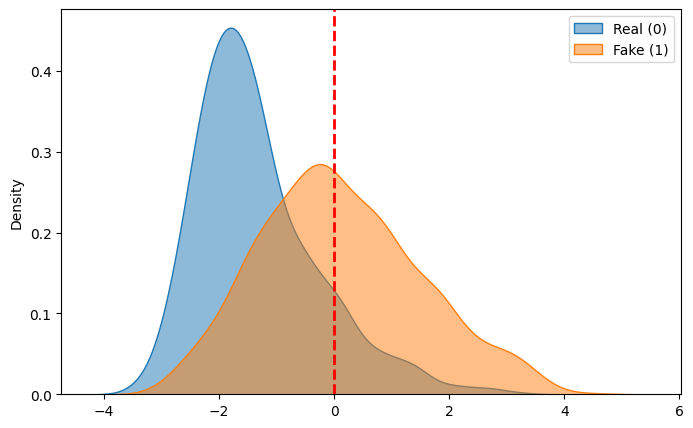


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 57.62%, EER: 44.21%
AUC: 56.73%, EER: 44.83%
AUC: 77.39%, EER: 26.67%
AUC: 71.72%, EER: 33.44%
AUC: 52.14%, EER: 47.82%
AUC: 56.31%, EER: 46.12%


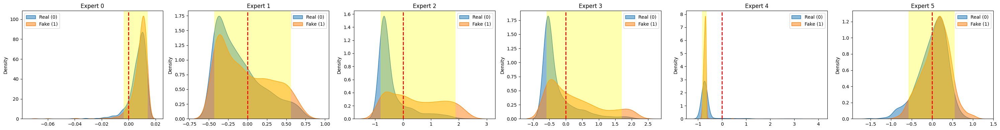


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 57.62%, EER: 44.21%
AUC: 38.02%, EER: 59.30%
AUC: 81.23%, EER: 26.67%
AUC: 73.13%, EER: 33.44%
AUC: 50.27%, EER: 47.82%
AUC: 56.31%, EER: 46.12%


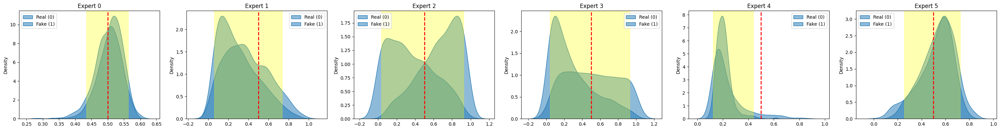


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 57.62%, EER: 44.21%
AUC: 38.02%, EER: 59.30%
AUC: 81.23%, EER: 26.67%
AUC: 73.13%, EER: 33.44%
AUC: 50.27%, EER: 47.82%
AUC: 56.31%, EER: 46.12%


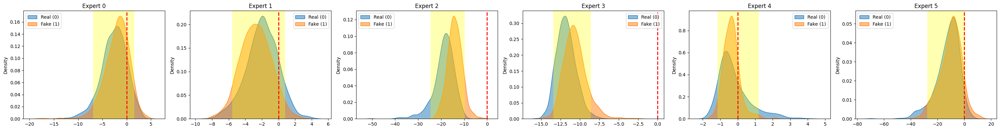


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 91.75%, EER: 15.52%


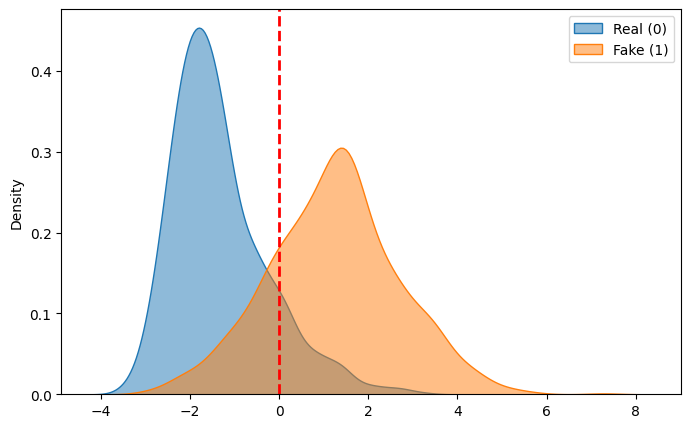


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 30.83%, EER: 63.45%
AUC: 79.29%, EER: 27.51%
AUC: 89.88%, EER: 16.37%
AUC: 70.73%, EER: 34.75%
AUC: 59.88%, EER: 42.44%
AUC: 52.62%, EER: 48.22%


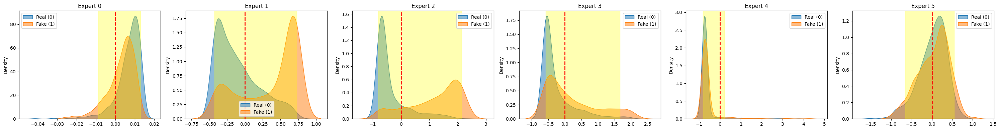


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 30.83%, EER: 63.45%
AUC: 16.08%, EER: 75.13%
AUC: 90.83%, EER: 16.37%
AUC: 72.41%, EER: 34.75%
AUC: 59.80%, EER: 41.98%
AUC: 52.62%, EER: 48.22%


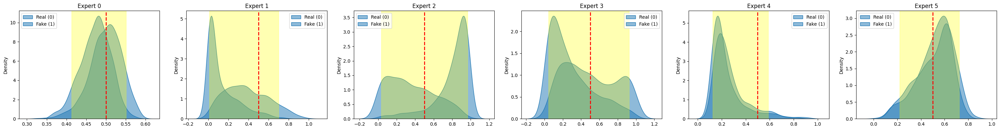


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 30.83%, EER: 63.45%
AUC: 16.08%, EER: 75.13%
AUC: 90.83%, EER: 16.37%
AUC: 72.41%, EER: 34.75%
AUC: 59.80%, EER: 41.98%
AUC: 52.62%, EER: 48.22%


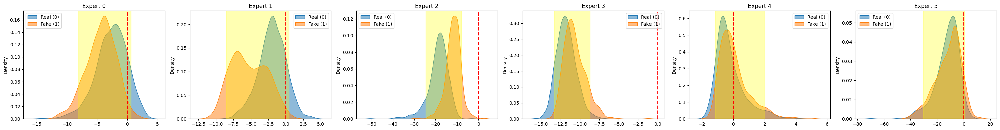


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 99.71%, EER: 2.66%


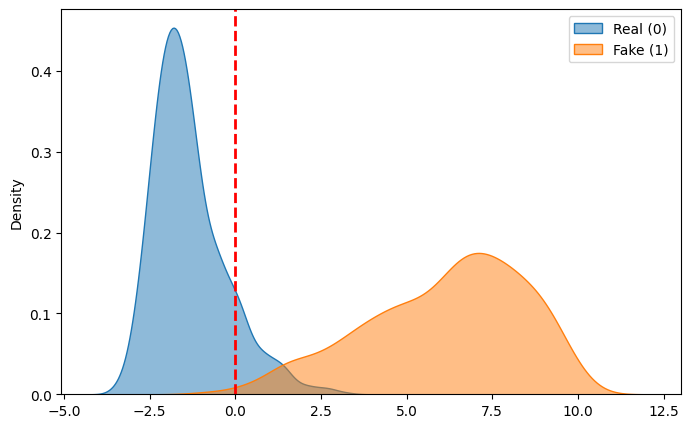


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 39.10%, EER: 58.45%
AUC: 72.30%, EER: 33.26%
AUC: 96.18%, EER: 10.10%
AUC: 87.60%, EER: 20.00%
AUC: 97.34%, EER: 7.17%
AUC: 55.71%, EER: 46.06%


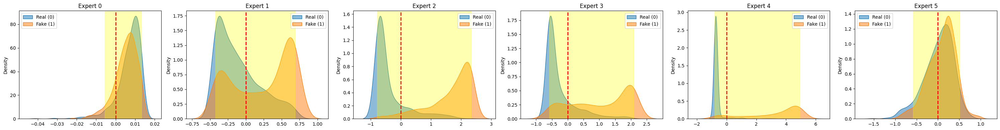


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 39.10%, EER: 58.45%
AUC: 22.04%, EER: 70.35%
AUC: 96.43%, EER: 10.10%
AUC: 88.08%, EER: 20.00%
AUC: 98.05%, EER: 7.17%
AUC: 55.71%, EER: 46.06%


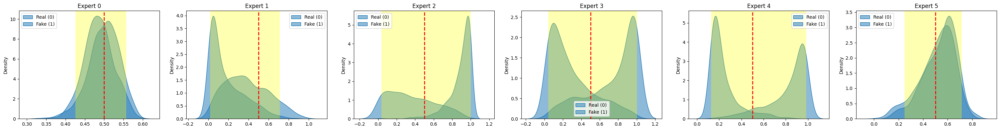


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 39.10%, EER: 58.45%
AUC: 22.04%, EER: 70.35%
AUC: 96.43%, EER: 10.10%
AUC: 88.08%, EER: 20.00%
AUC: 98.05%, EER: 7.17%
AUC: 55.71%, EER: 46.06%


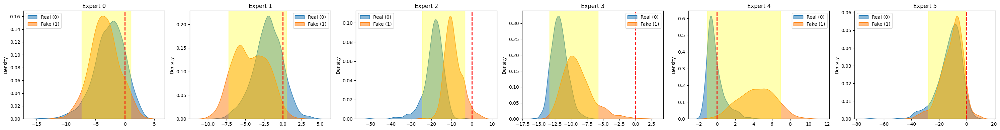


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 82.66%, EER: 26.46%


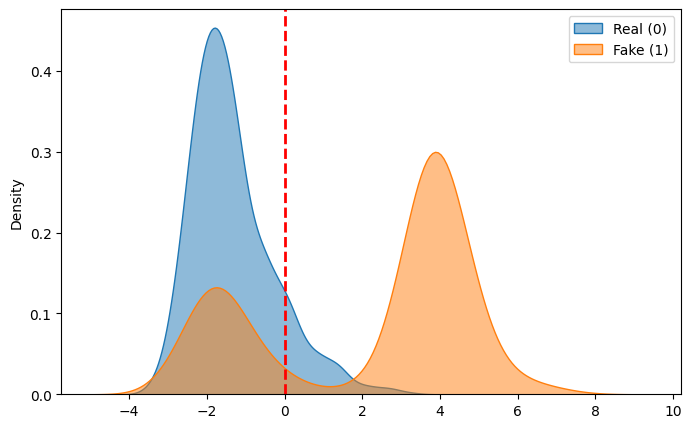


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 56.84%, EER: 45.48%
AUC: 53.75%, EER: 44.41%
AUC: 45.75%, EER: 51.54%
AUC: 46.05%, EER: 55.26%
AUC: 89.35%, EER: 22.00%
AUC: 48.80%, EER: 51.86%


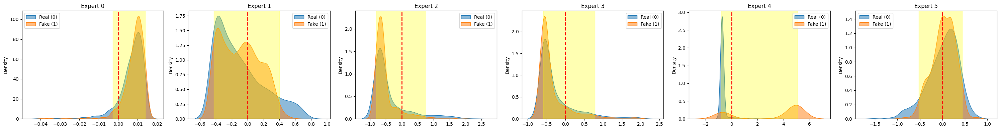


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 56.84%, EER: 45.48%
AUC: 77.23%, EER: 30.46%
AUC: 39.87%, EER: 56.54%
AUC: 41.25%, EER: 56.11%
AUC: 88.86%, EER: 23.64%
AUC: 48.80%, EER: 51.86%


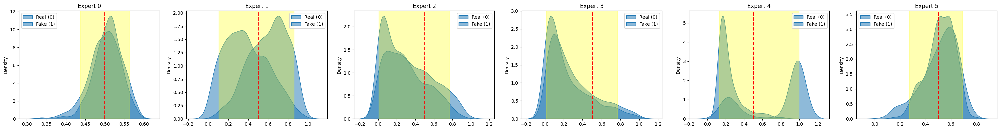


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 56.84%, EER: 45.48%
AUC: 77.23%, EER: 30.46%
AUC: 39.87%, EER: 56.54%
AUC: 41.25%, EER: 56.11%
AUC: 88.86%, EER: 23.64%
AUC: 48.80%, EER: 51.86%


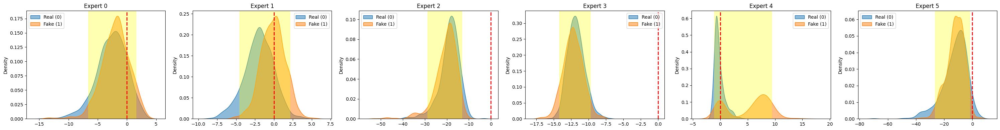


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 84.87%, EER: 23.12%


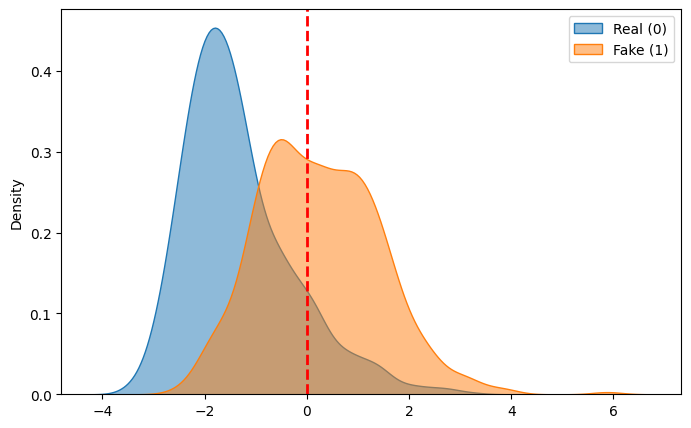


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 28.99%, EER: 64.61%
AUC: 82.56%, EER: 23.82%
AUC: 46.19%, EER: 53.13%
AUC: 83.41%, EER: 24.02%
AUC: 66.95%, EER: 37.30%
AUC: 70.38%, EER: 35.18%


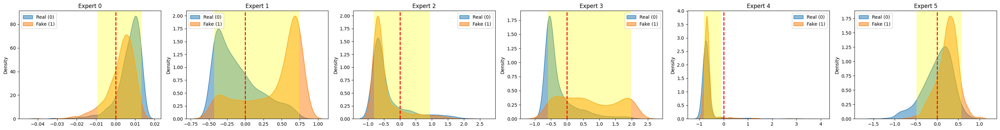


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 28.99%, EER: 64.61%
AUC: 13.25%, EER: 78.18%
AUC: 45.08%, EER: 53.99%
AUC: 83.97%, EER: 24.02%
AUC: 67.00%, EER: 36.24%
AUC: 70.38%, EER: 35.18%


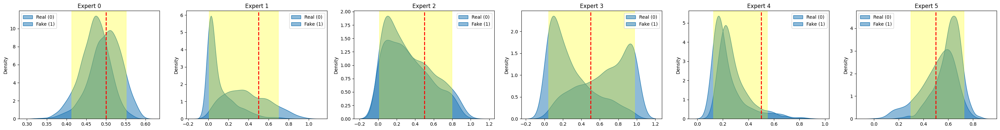


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 28.99%, EER: 64.61%
AUC: 13.25%, EER: 78.18%
AUC: 45.08%, EER: 53.99%
AUC: 83.97%, EER: 24.02%
AUC: 67.00%, EER: 36.24%
AUC: 70.38%, EER: 35.18%


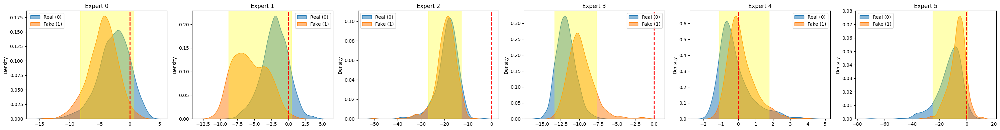


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 98.22%, EER: 6.65%


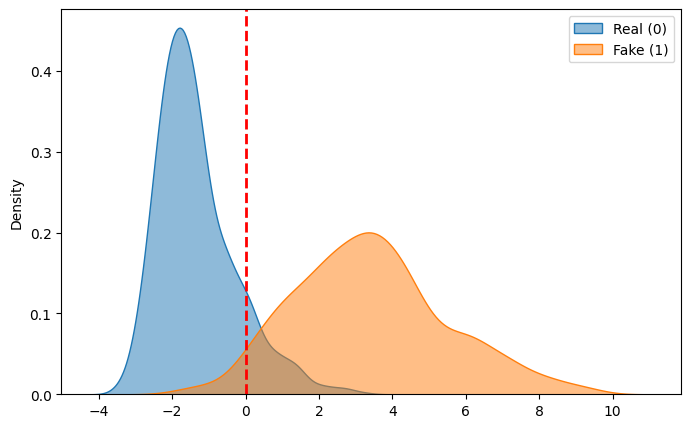


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 47.09%, EER: 51.51%
AUC: 65.28%, EER: 39.53%
AUC: 81.78%, EER: 23.59%
AUC: 97.08%, EER: 8.82%
AUC: 83.24%, EER: 26.41%
AUC: 63.36%, EER: 41.83%


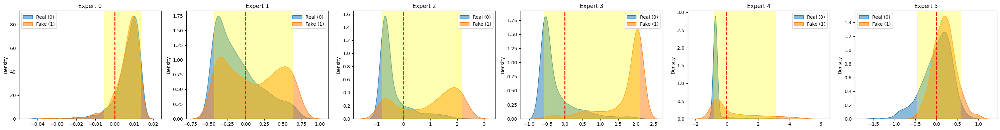


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 47.09%, EER: 51.51%
AUC: 30.23%, EER: 64.72%
AUC: 84.26%, EER: 23.59%
AUC: 97.17%, EER: 8.82%
AUC: 85.99%, EER: 20.94%
AUC: 63.36%, EER: 41.83%


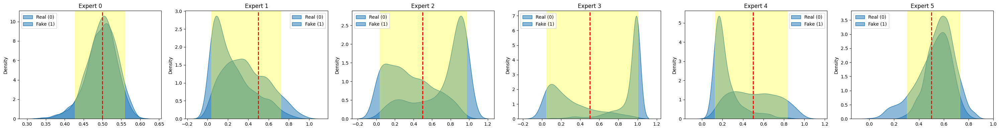


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 47.09%, EER: 51.51%
AUC: 30.23%, EER: 64.72%
AUC: 84.26%, EER: 23.59%
AUC: 97.17%, EER: 8.82%
AUC: 85.99%, EER: 20.94%
AUC: 63.36%, EER: 41.83%


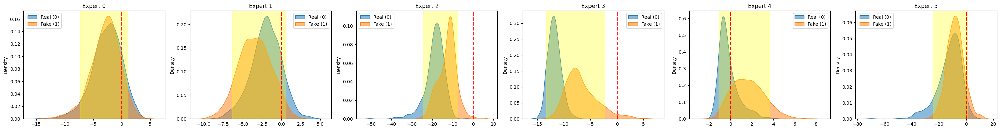


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 100.00%, EER: 0.10%


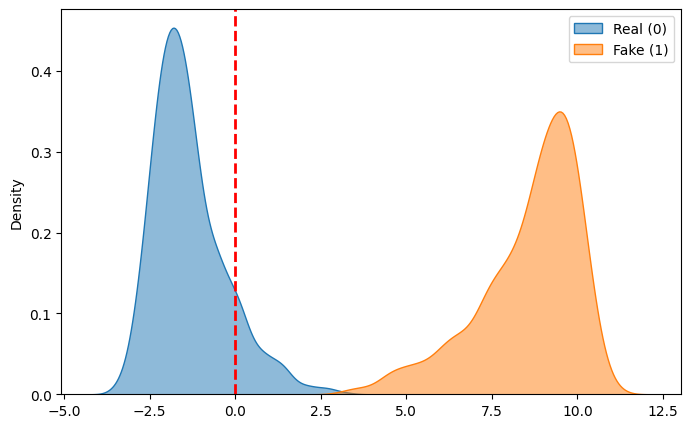


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 26.06%, EER: 67.94%
AUC: 82.27%, EER: 25.65%
AUC: 95.39%, EER: 11.12%
AUC: 98.97%, EER: 4.71%
AUC: 99.59%, EER: 3.01%
AUC: 67.11%, EER: 39.64%


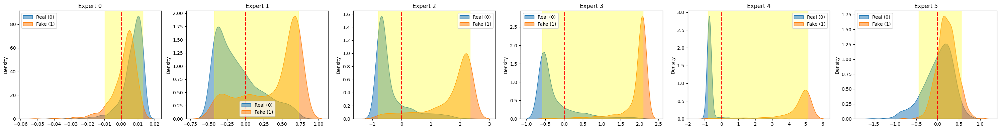


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 26.06%, EER: 67.94%
AUC: 13.62%, EER: 78.46%
AUC: 95.77%, EER: 11.12%
AUC: 98.97%, EER: 4.71%
AUC: 99.70%, EER: 3.01%
AUC: 67.11%, EER: 39.64%


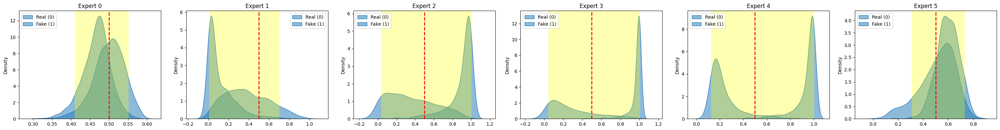


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 26.06%, EER: 67.94%
AUC: 13.62%, EER: 78.46%
AUC: 95.77%, EER: 11.12%
AUC: 98.97%, EER: 4.71%
AUC: 99.70%, EER: 3.01%
AUC: 67.11%, EER: 39.64%


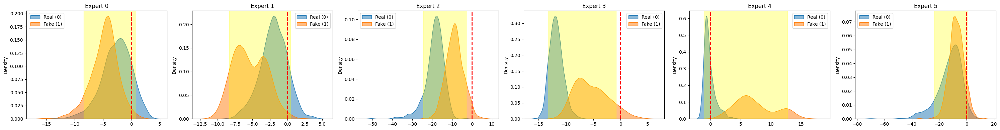


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 69.28%, EER: 36.13%


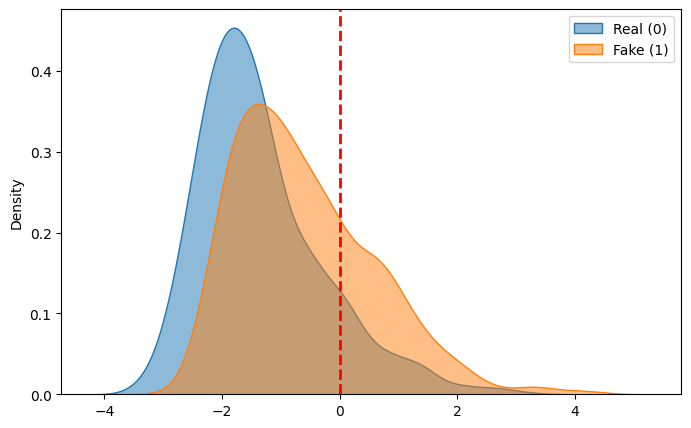


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 43.05%, EER: 55.47%
AUC: 58.04%, EER: 44.51%
AUC: 52.51%, EER: 48.69%
AUC: 67.43%, EER: 36.05%
AUC: 63.96%, EER: 39.96%
AUC: 65.12%, EER: 38.56%


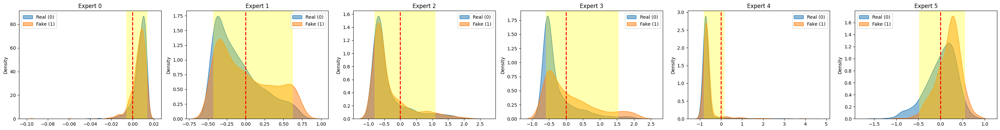


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 43.05%, EER: 55.47%
AUC: 39.44%, EER: 57.26%
AUC: 52.23%, EER: 47.23%
AUC: 68.30%, EER: 36.05%
AUC: 64.10%, EER: 39.43%
AUC: 65.12%, EER: 38.56%


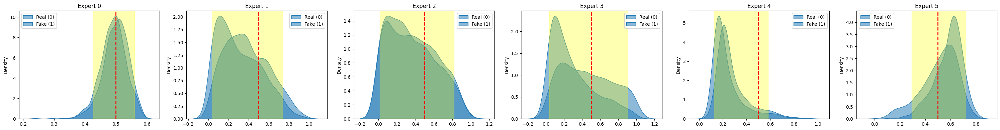


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 43.05%, EER: 55.47%
AUC: 39.44%, EER: 57.26%
AUC: 52.23%, EER: 47.23%
AUC: 68.30%, EER: 36.05%
AUC: 64.10%, EER: 39.43%
AUC: 65.12%, EER: 38.56%


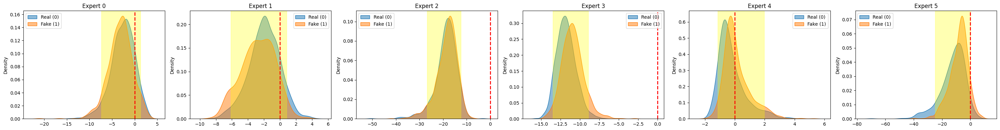


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 99.59%, EER: 2.91%


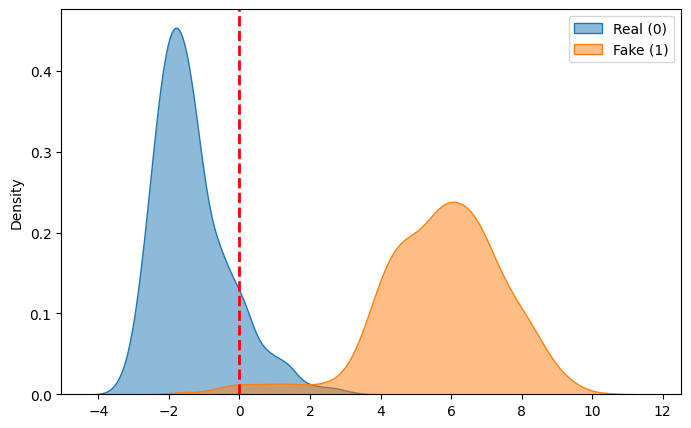


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 41.55%, EER: 56.11%
AUC: 59.40%, EER: 43.36%
AUC: 78.64%, EER: 26.33%
AUC: 77.57%, EER: 29.33%
AUC: 99.14%, EER: 3.64%
AUC: 70.51%, EER: 34.96%


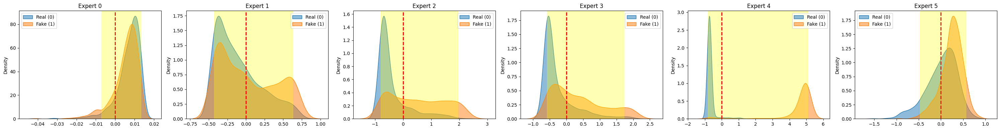


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 41.55%, EER: 56.11%
AUC: 36.79%, EER: 59.31%
AUC: 79.07%, EER: 26.33%
AUC: 78.28%, EER: 29.33%
AUC: 99.19%, EER: 3.64%
AUC: 70.51%, EER: 34.96%


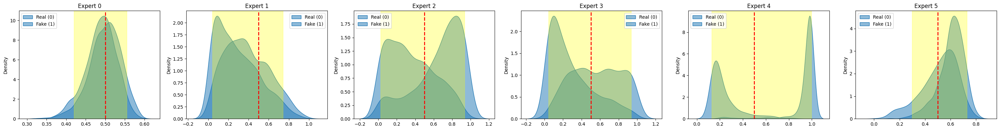


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 41.55%, EER: 56.11%
AUC: 36.79%, EER: 59.31%
AUC: 79.07%, EER: 26.33%
AUC: 78.28%, EER: 29.33%
AUC: 99.19%, EER: 3.64%
AUC: 70.51%, EER: 34.96%


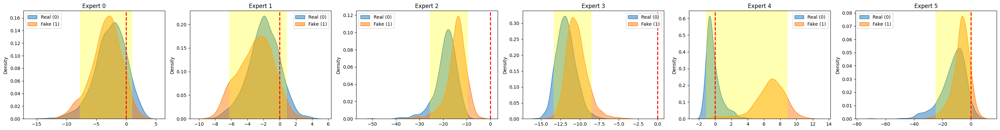


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 98.18%, EER: 4.71%


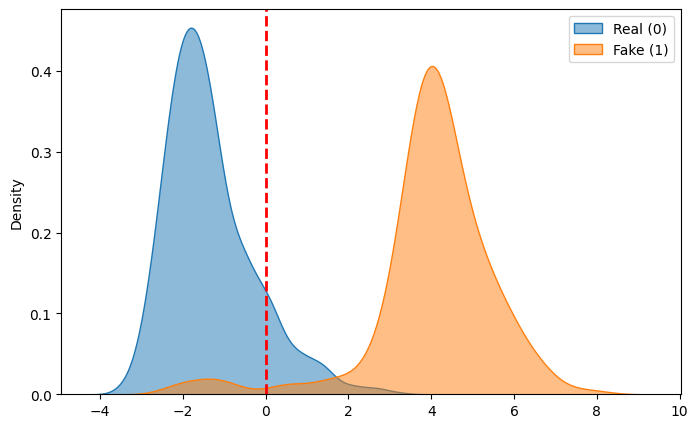


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 45.30%, EER: 54.55%
AUC: 55.56%, EER: 46.76%
AUC: 45.60%, EER: 51.87%
AUC: 58.07%, EER: 43.78%
AUC: 99.25%, EER: 3.74%
AUC: 55.61%, EER: 46.95%


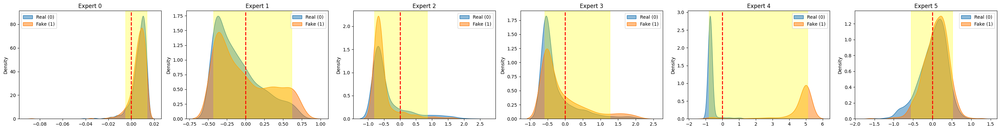


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 45.30%, EER: 54.55%
AUC: 41.08%, EER: 55.69%
AUC: 40.92%, EER: 57.01%
AUC: 59.22%, EER: 43.78%
AUC: 99.18%, EER: 3.74%
AUC: 55.61%, EER: 46.95%


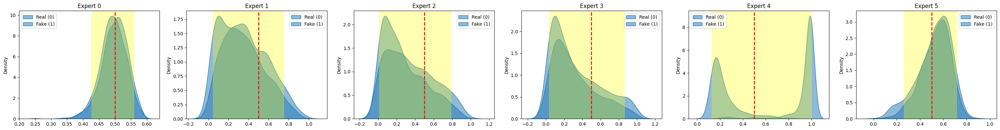


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 45.30%, EER: 54.55%
AUC: 41.08%, EER: 55.69%
AUC: 40.92%, EER: 57.01%
AUC: 59.22%, EER: 43.78%
AUC: 99.18%, EER: 3.74%
AUC: 55.61%, EER: 46.95%


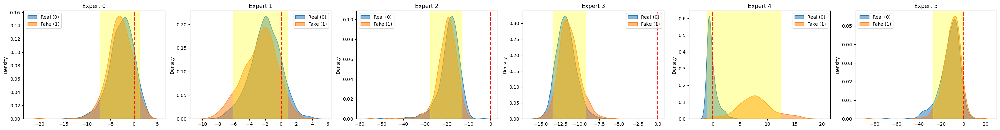

In [5]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/6_experts/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            if title == "Scaled Logits":
                thr = 0.5
            else:
                thr = 0

            lbound = np.percentile(scores, 5)
            hbound = np.percentile(scores, 95)

            plot_distributions(scores, labels, lbound, hbound, thr=thr, ax=ax, metrics=True)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()

# Test set: ASVspoof 5

In [4]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14', 'A17', 'A19', 'A21', 'A22', 'A28', 'A29']    

score_types = [
    ("LogLR scores", "scores_per_expert.npy"),
    ("Scaled Logits", "scaled_logits_per_expert.npy"),
    ("Raw Logits", "raw_logits_per_expert.npy"),
]


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 42.85%, EER: 57.06%


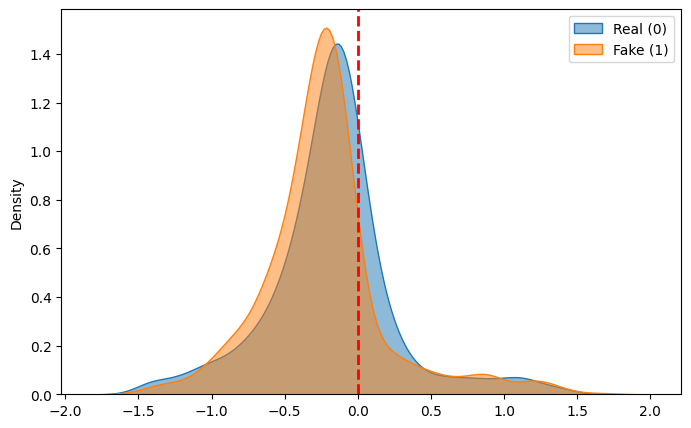


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 50.85%, EER: 50.25%
AUC: 38.98%, EER: 59.46%
AUC: 49.54%, EER: 48.85%
AUC: 48.86%, EER: 51.25%
AUC: 24.30%, EER: 68.97%
AUC: 73.04%, EER: 32.93%


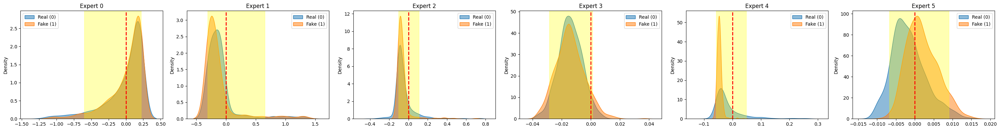


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 50.96%, EER: 50.25%
AUC: 62.40%, EER: 42.02%
AUC: 67.10%, EER: 33.47%
AUC: 51.14%, EER: 48.75%
AUC: 24.30%, EER: 68.97%
AUC: 26.96%, EER: 67.07%


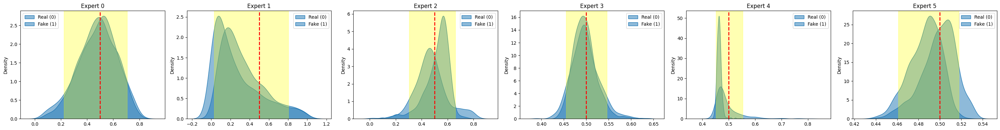


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 50.96%, EER: 50.25%
AUC: 62.40%, EER: 42.02%
AUC: 67.10%, EER: 33.47%
AUC: 51.14%, EER: 48.75%
AUC: 24.30%, EER: 68.97%
AUC: 26.96%, EER: 67.07%


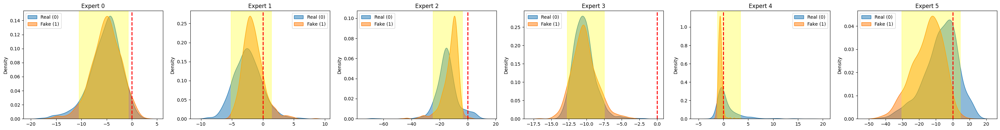


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 42.79%, EER: 57.16%


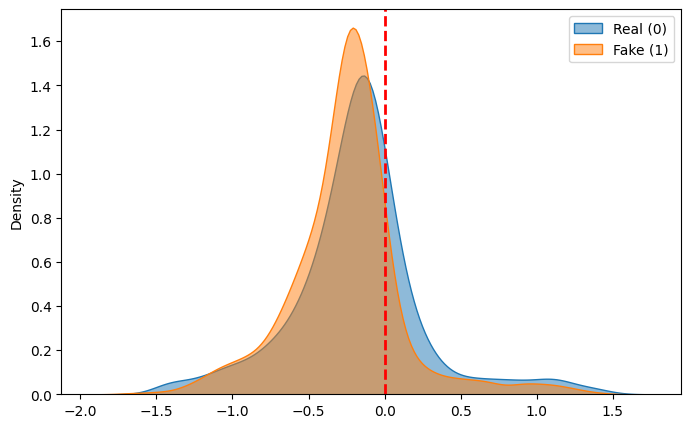


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 53.10%, EER: 48.50%
AUC: 38.15%, EER: 59.42%
AUC: 49.17%, EER: 49.02%
AUC: 48.12%, EER: 51.60%
AUC: 24.07%, EER: 69.41%
AUC: 72.92%, EER: 33.70%


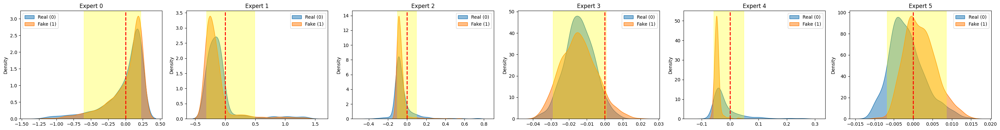


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 53.02%, EER: 48.50%
AUC: 60.20%, EER: 42.74%
AUC: 70.18%, EER: 30.28%
AUC: 51.88%, EER: 48.40%
AUC: 24.07%, EER: 69.41%
AUC: 27.08%, EER: 66.30%


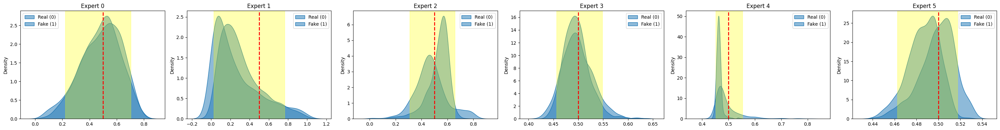


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 53.02%, EER: 48.50%
AUC: 60.20%, EER: 42.74%
AUC: 70.18%, EER: 30.28%
AUC: 51.88%, EER: 48.40%
AUC: 24.07%, EER: 69.41%
AUC: 27.08%, EER: 66.30%


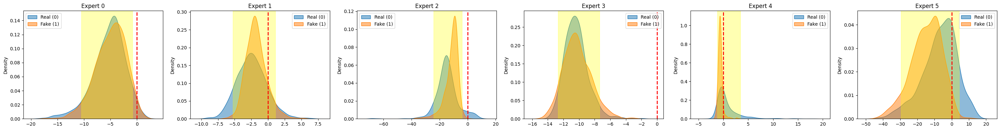


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 39.10%, EER: 58.60%


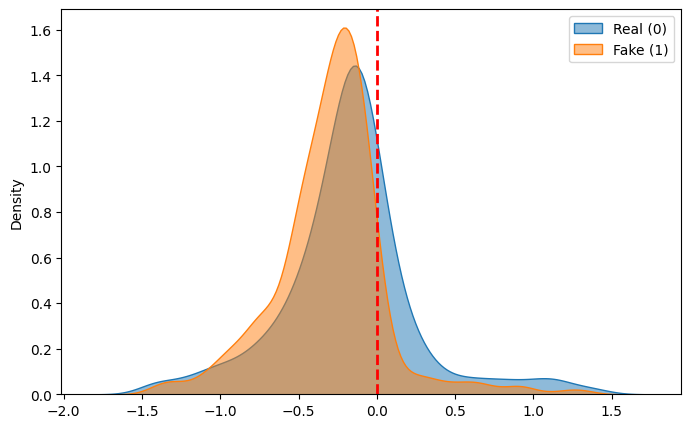


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 49.88%, EER: 50.77%
AUC: 36.51%, EER: 60.30%
AUC: 50.36%, EER: 48.51%
AUC: 40.72%, EER: 57.36%
AUC: 24.92%, EER: 69.52%
AUC: 72.97%, EER: 33.68%


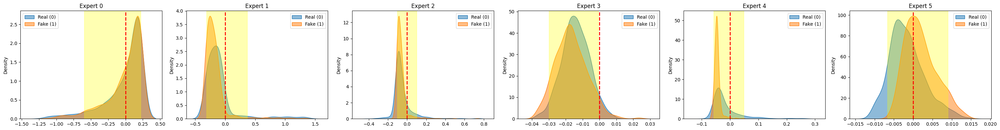


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 49.75%, EER: 50.77%
AUC: 57.96%, EER: 44.90%
AUC: 68.70%, EER: 32.23%
AUC: 59.28%, EER: 42.64%
AUC: 24.92%, EER: 69.52%
AUC: 27.03%, EER: 66.32%


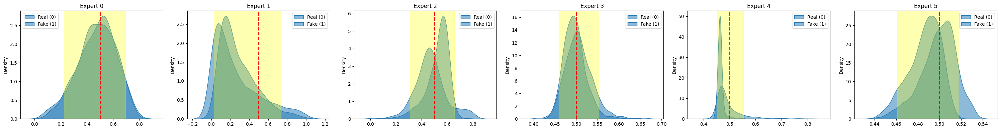


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 49.75%, EER: 50.77%
AUC: 57.96%, EER: 44.90%
AUC: 68.70%, EER: 32.23%
AUC: 59.28%, EER: 42.64%
AUC: 24.92%, EER: 69.52%
AUC: 27.03%, EER: 66.32%


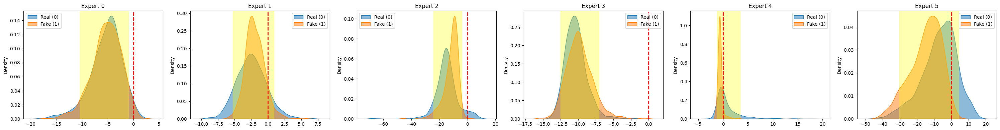


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 45.36%, EER: 55.41%


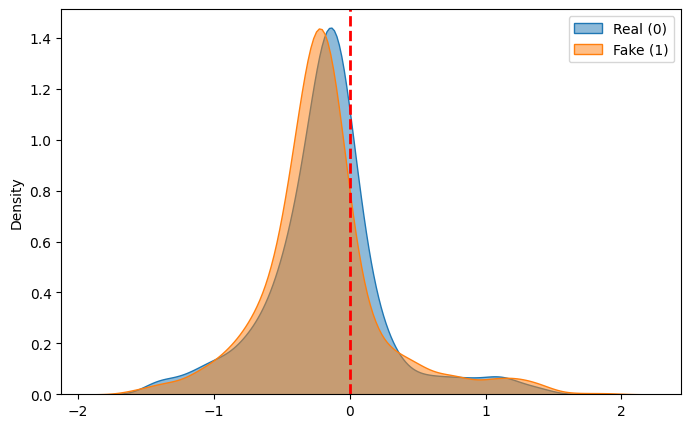


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 51.54%, EER: 49.75%
AUC: 38.07%, EER: 59.74%
AUC: 52.06%, EER: 49.12%
AUC: 36.23%, EER: 60.35%
AUC: 30.13%, EER: 65.81%
AUC: 76.82%, EER: 29.66%


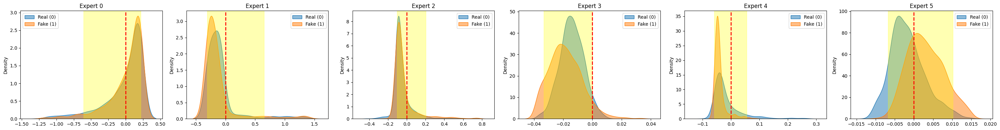


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 51.54%, EER: 49.75%
AUC: 60.73%, EER: 42.89%
AUC: 56.04%, EER: 40.68%
AUC: 63.78%, EER: 39.65%
AUC: 30.13%, EER: 65.81%
AUC: 23.18%, EER: 70.34%


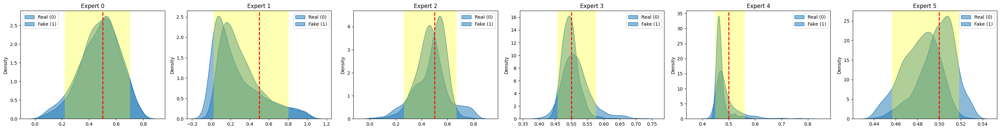


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 51.54%, EER: 49.75%
AUC: 60.73%, EER: 42.89%
AUC: 56.04%, EER: 40.68%
AUC: 63.78%, EER: 39.65%
AUC: 30.13%, EER: 65.81%
AUC: 23.18%, EER: 70.34%


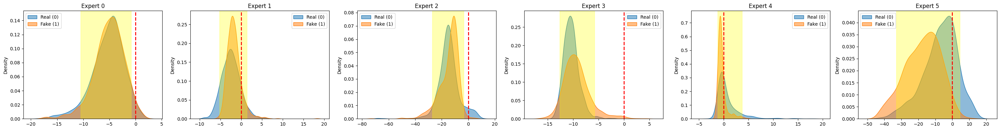


########################################################################################################################
#--------------------------------------------------------- A05 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 43.99%, EER: 55.92%


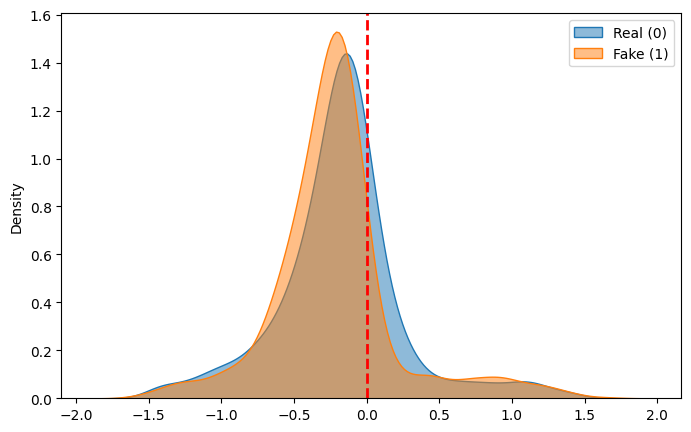


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 49.71%, EER: 51.08%
AUC: 40.49%, EER: 58.29%
AUC: 48.85%, EER: 50.50%
AUC: 31.63%, EER: 63.75%
AUC: 31.48%, EER: 65.16%
AUC: 78.37%, EER: 28.42%


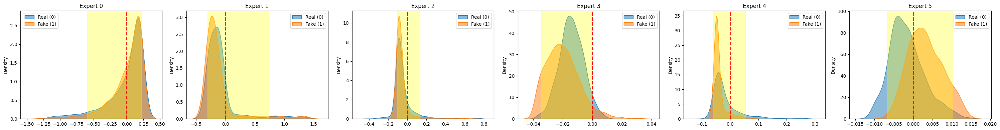


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 49.63%, EER: 51.08%
AUC: 59.39%, EER: 43.98%
AUC: 62.11%, EER: 37.55%
AUC: 68.38%, EER: 36.25%
AUC: 31.48%, EER: 65.16%
AUC: 21.63%, EER: 71.58%


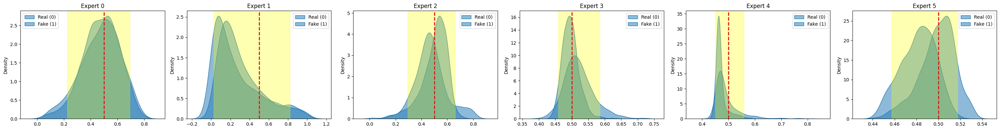


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 49.63%, EER: 51.08%
AUC: 59.39%, EER: 43.98%
AUC: 62.11%, EER: 37.55%
AUC: 68.38%, EER: 36.25%
AUC: 31.48%, EER: 65.16%
AUC: 21.63%, EER: 71.58%


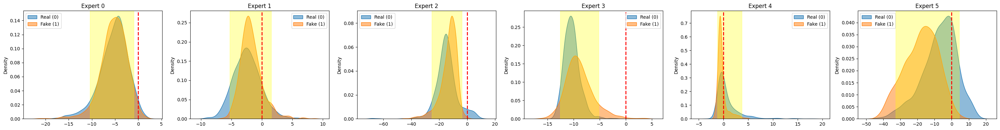


########################################################################################################################
#--------------------------------------------------------- A06 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 43.94%, EER: 56.02%


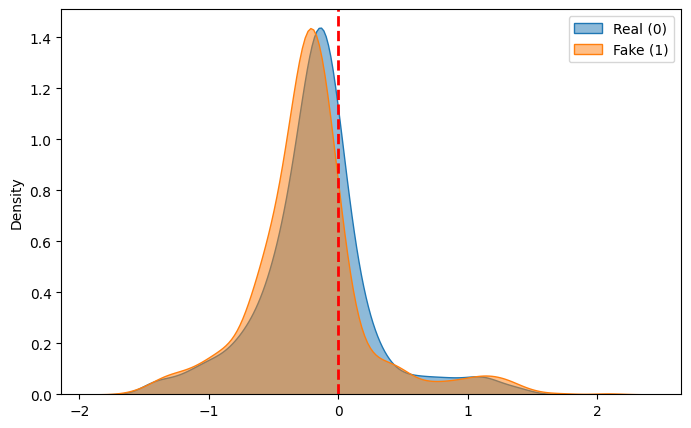


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 48.65%, EER: 52.01%
AUC: 41.58%, EER: 55.61%
AUC: 50.10%, EER: 49.33%
AUC: 39.09%, EER: 57.53%
AUC: 26.48%, EER: 69.41%
AUC: 78.11%, EER: 28.73%


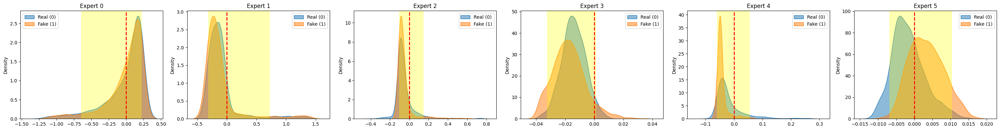


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 48.53%, EER: 52.01%
AUC: 58.88%, EER: 43.98%
AUC: 62.47%, EER: 37.25%
AUC: 60.91%, EER: 42.47%
AUC: 26.48%, EER: 69.41%
AUC: 21.89%, EER: 71.27%


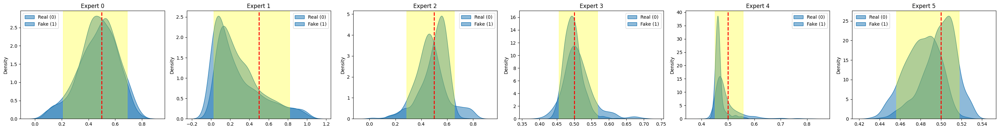


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 48.53%, EER: 52.01%
AUC: 58.88%, EER: 43.98%
AUC: 62.47%, EER: 37.25%
AUC: 60.91%, EER: 42.47%
AUC: 26.48%, EER: 69.41%
AUC: 21.89%, EER: 71.27%


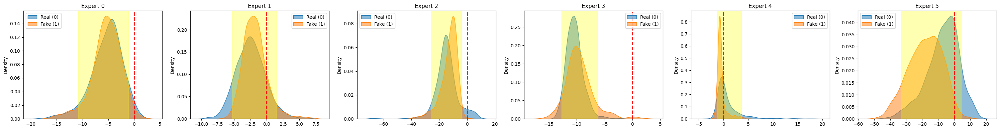


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 39.96%, EER: 56.46%


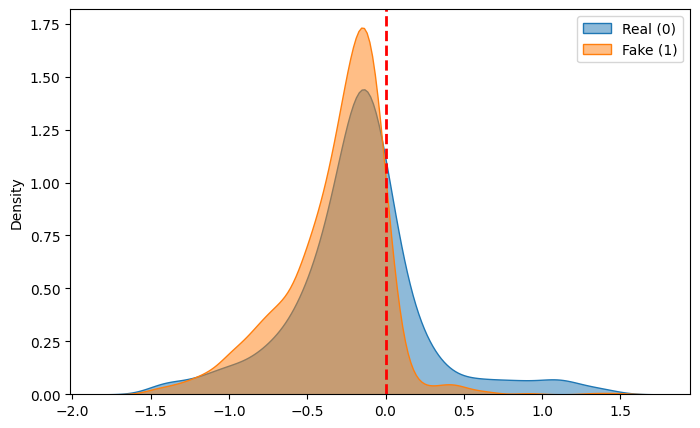


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 42.42%, EER: 55.72%
AUC: 53.69%, EER: 45.11%
AUC: 57.38%, EER: 41.81%
AUC: 28.52%, EER: 66.47%
AUC: 19.58%, EER: 72.97%
AUC: 76.72%, EER: 29.97%


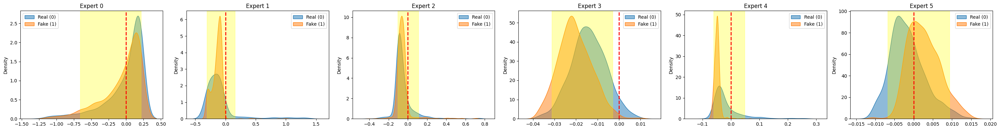


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 42.32%, EER: 55.72%
AUC: 32.82%, EER: 63.95%
AUC: 75.79%, EER: 25.54%
AUC: 71.48%, EER: 33.53%
AUC: 19.58%, EER: 72.97%
AUC: 23.28%, EER: 70.03%


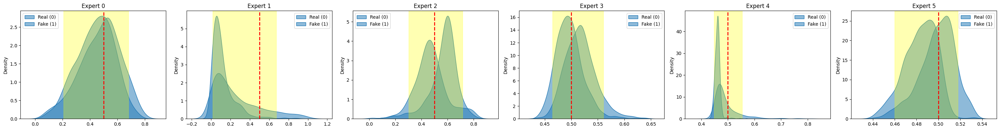


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 42.32%, EER: 55.72%
AUC: 32.82%, EER: 63.95%
AUC: 75.79%, EER: 25.54%
AUC: 71.48%, EER: 33.53%
AUC: 19.58%, EER: 72.97%
AUC: 23.28%, EER: 70.03%


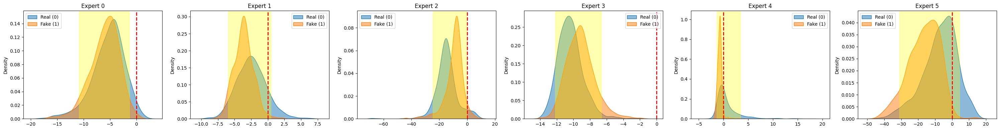


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 34.43%, EER: 61.38%


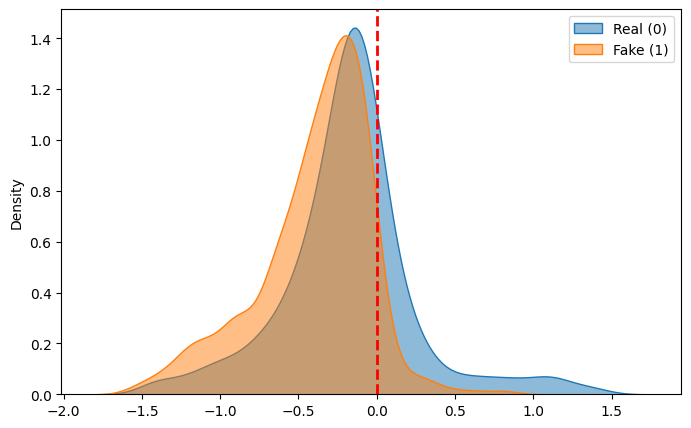


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 36.95%, EER: 59.76%
AUC: 49.14%, EER: 48.25%
AUC: 42.00%, EER: 56.06%
AUC: 50.92%, EER: 49.23%
AUC: 29.75%, EER: 65.91%
AUC: 58.35%, EER: 45.05%


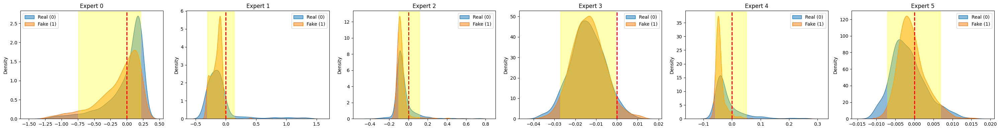


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 36.83%, EER: 59.76%
AUC: 37.59%, EER: 59.36%
AUC: 62.52%, EER: 37.28%
AUC: 49.08%, EER: 50.77%
AUC: 29.75%, EER: 65.91%
AUC: 41.65%, EER: 54.95%


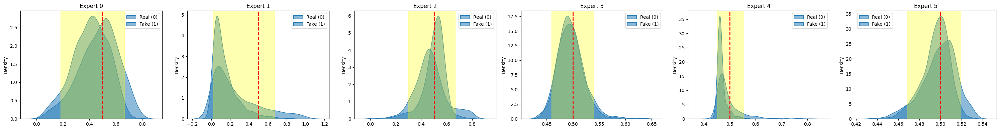


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 36.83%, EER: 59.76%
AUC: 37.59%, EER: 59.36%
AUC: 62.52%, EER: 37.28%
AUC: 49.08%, EER: 50.77%
AUC: 29.75%, EER: 65.91%
AUC: 41.65%, EER: 54.95%


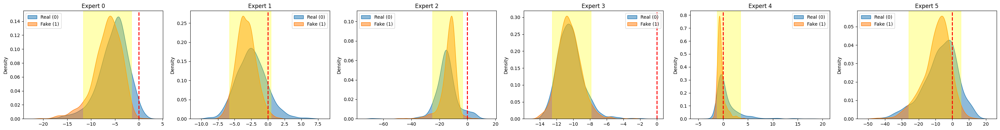


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 45.25%, EER: 51.30%


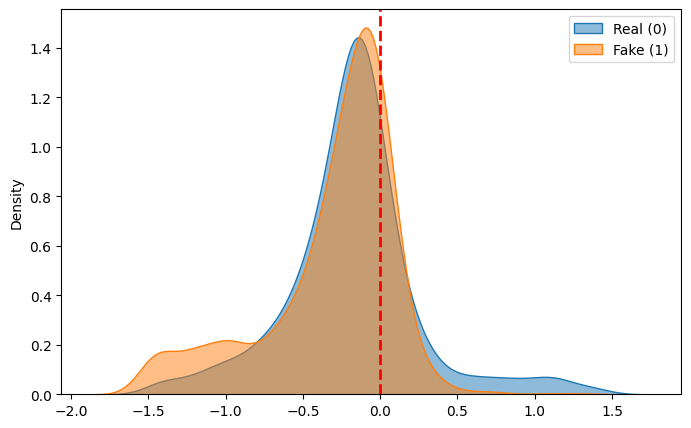


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 42.22%, EER: 55.20%
AUC: 52.06%, EER: 46.90%
AUC: 39.91%, EER: 57.88%
AUC: 36.48%, EER: 59.40%
AUC: 75.46%, EER: 30.59%
AUC: 80.63%, EER: 27.09%


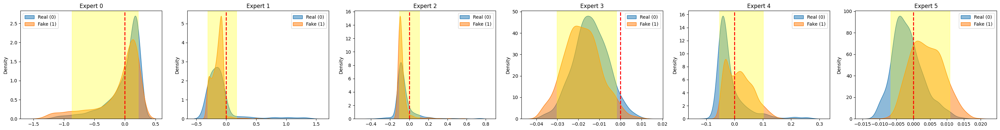


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 42.04%, EER: 55.20%
AUC: 36.65%, EER: 59.94%
AUC: 57.53%, EER: 42.30%
AUC: 63.53%, EER: 40.60%
AUC: 75.46%, EER: 30.59%
AUC: 19.37%, EER: 72.91%


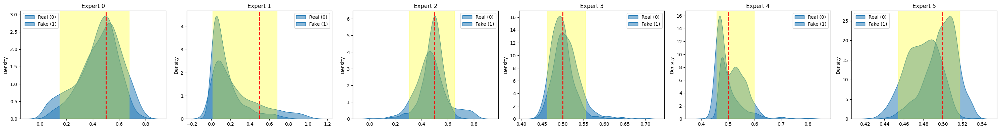


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 42.04%, EER: 55.20%
AUC: 36.65%, EER: 59.94%
AUC: 57.53%, EER: 42.30%
AUC: 63.53%, EER: 40.60%
AUC: 75.46%, EER: 30.59%
AUC: 19.37%, EER: 72.91%


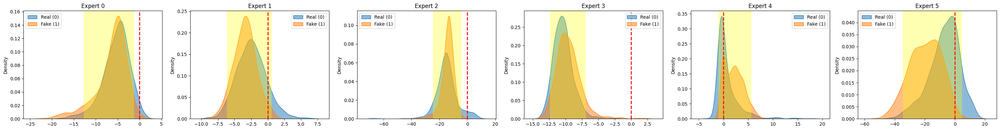


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 46.31%, EER: 51.50%


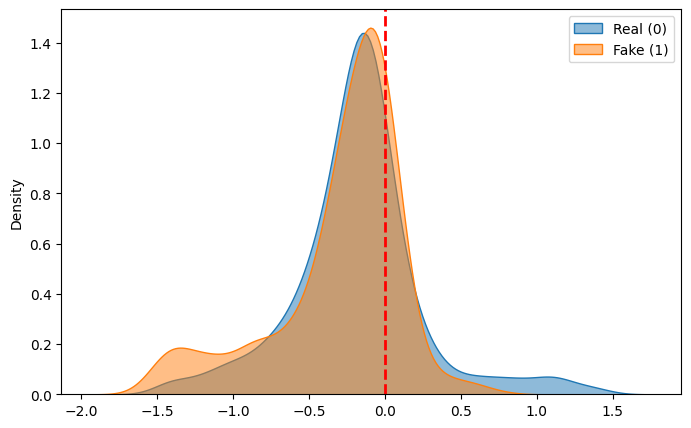


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 44.16%, EER: 53.86%
AUC: 50.69%, EER: 47.60%
AUC: 41.80%, EER: 56.85%
AUC: 35.97%, EER: 60.45%
AUC: 75.54%, EER: 30.59%
AUC: 79.96%, EER: 27.09%


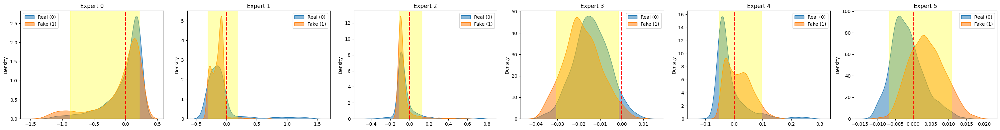


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 44.03%, EER: 53.86%
AUC: 37.45%, EER: 58.70%
AUC: 55.72%, EER: 43.15%
AUC: 64.03%, EER: 39.55%
AUC: 75.54%, EER: 30.59%
AUC: 20.04%, EER: 72.91%


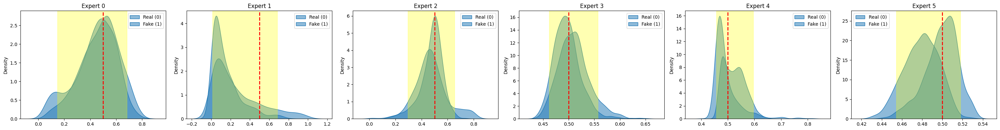


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 44.03%, EER: 53.86%
AUC: 37.45%, EER: 58.70%
AUC: 55.72%, EER: 43.15%
AUC: 64.03%, EER: 39.55%
AUC: 75.54%, EER: 30.59%
AUC: 20.04%, EER: 72.91%


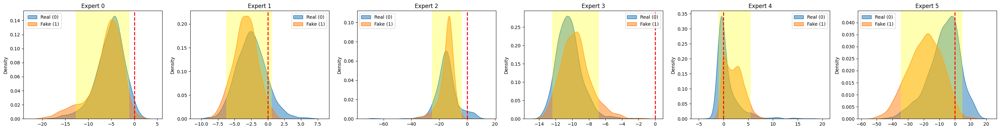


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 51.02%, EER: 51.18%


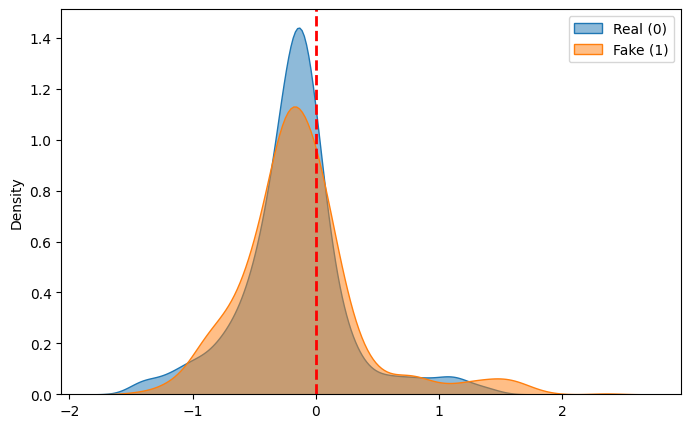


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 42.92%, EER: 56.33%
AUC: 49.03%, EER: 49.69%
AUC: 43.82%, EER: 55.61%
AUC: 63.51%, EER: 40.16%
AUC: 63.39%, EER: 46.61%
AUC: 77.42%, EER: 28.64%


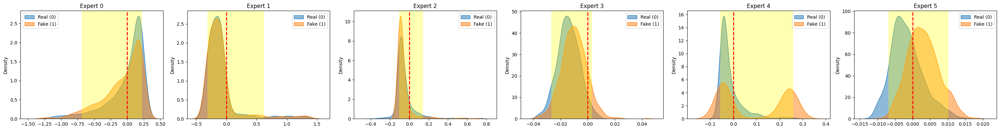


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 43.04%, EER: 56.33%
AUC: 49.65%, EER: 49.43%
AUC: 52.09%, EER: 46.65%
AUC: 36.49%, EER: 59.84%
AUC: 63.39%, EER: 46.61%
AUC: 22.58%, EER: 71.36%


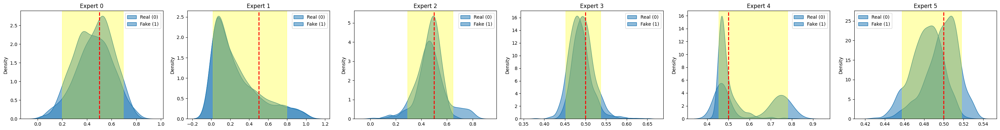


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 43.04%, EER: 56.33%
AUC: 49.65%, EER: 49.43%
AUC: 52.09%, EER: 46.65%
AUC: 36.49%, EER: 59.84%
AUC: 63.39%, EER: 46.61%
AUC: 22.58%, EER: 71.36%


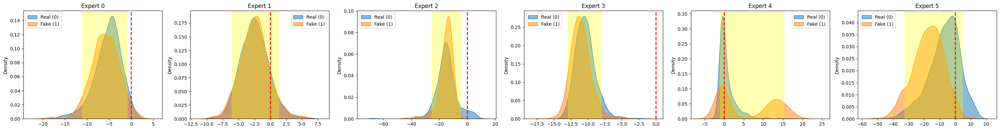


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 86.35%, EER: 20.24%


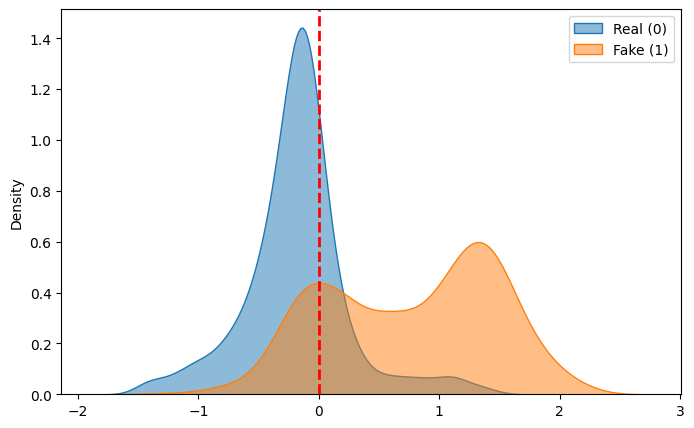


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 63.91%, EER: 39.75%
AUC: 77.57%, EER: 26.95%
AUC: 78.59%, EER: 28.94%
AUC: 80.35%, EER: 27.60%
AUC: 49.68%, EER: 50.98%
AUC: 61.45%, EER: 42.59%


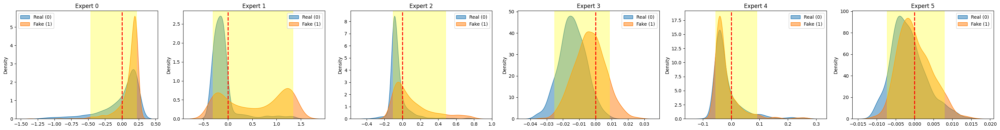


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 64.27%, EER: 39.75%
AUC: 89.38%, EER: 18.54%
AUC: 17.61%, EER: 73.95%
AUC: 19.65%, EER: 72.40%
AUC: 49.68%, EER: 50.98%
AUC: 38.55%, EER: 57.41%


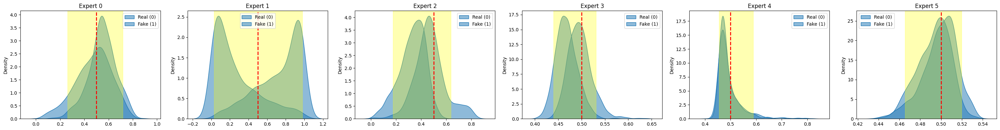


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 64.27%, EER: 39.75%
AUC: 89.38%, EER: 18.54%
AUC: 17.61%, EER: 73.95%
AUC: 19.65%, EER: 72.40%
AUC: 49.68%, EER: 50.98%
AUC: 38.55%, EER: 57.41%


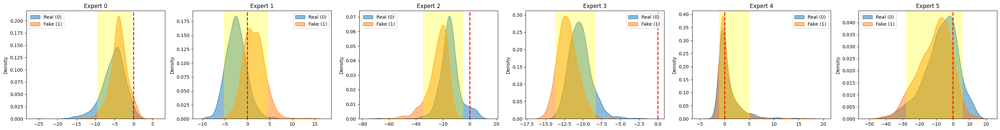


########################################################################################################################
#--------------------------------------------------------- A14 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 46.19%, EER: 52.42%


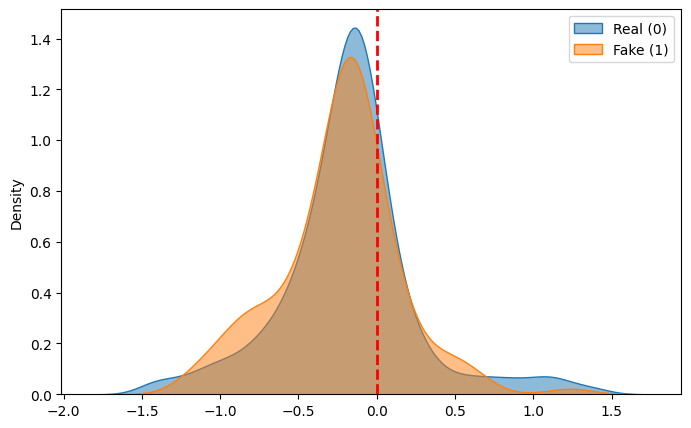


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 49.30%, EER: 52.11%
AUC: 56.63%, EER: 44.00%
AUC: 44.98%, EER: 56.80%
AUC: 40.39%, EER: 56.80%
AUC: 23.44%, EER: 71.37%
AUC: 79.98%, EER: 27.81%


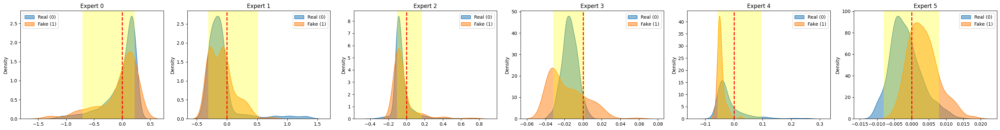


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 50.63%, EER: 52.11%
AUC: 69.22%, EER: 26.88%
AUC: 47.91%, EER: 48.40%
AUC: 59.70%, EER: 43.20%
AUC: 23.44%, EER: 71.37%
AUC: 20.02%, EER: 72.19%


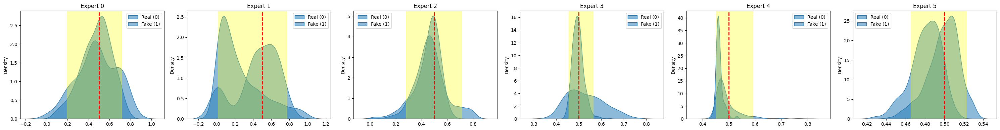


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 50.63%, EER: 52.11%
AUC: 69.22%, EER: 26.88%
AUC: 47.91%, EER: 48.40%
AUC: 59.70%, EER: 43.20%
AUC: 23.44%, EER: 71.37%
AUC: 20.02%, EER: 72.19%


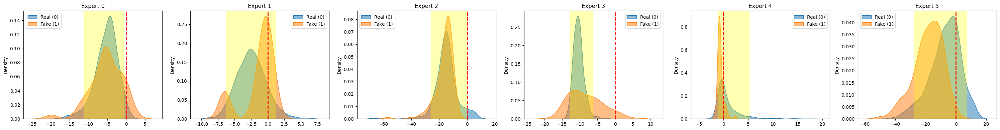


########################################################################################################################
#--------------------------------------------------------- A17 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 48.87%, EER: 51.31%


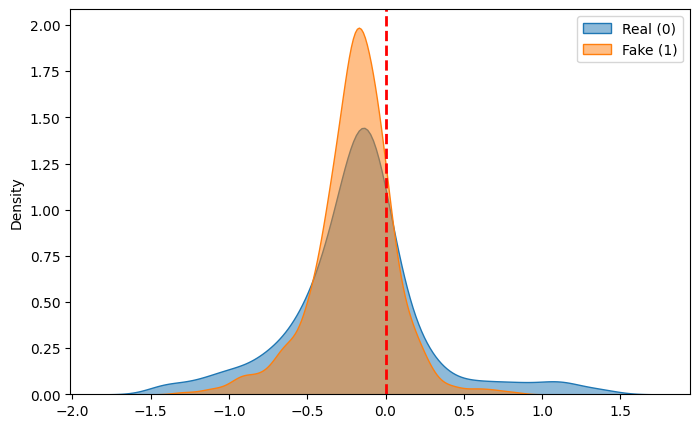


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 54.83%, EER: 47.58%
AUC: 43.43%, EER: 53.55%
AUC: 47.54%, EER: 52.41%
AUC: 43.15%, EER: 55.42%
AUC: 56.37%, EER: 45.98%
AUC: 46.00%, EER: 53.01%


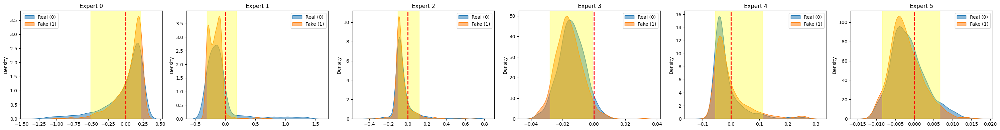


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 54.84%, EER: 47.58%
AUC: 46.37%, EER: 52.71%
AUC: 50.33%, EER: 49.60%
AUC: 56.85%, EER: 44.58%
AUC: 56.37%, EER: 45.98%
AUC: 54.00%, EER: 46.99%


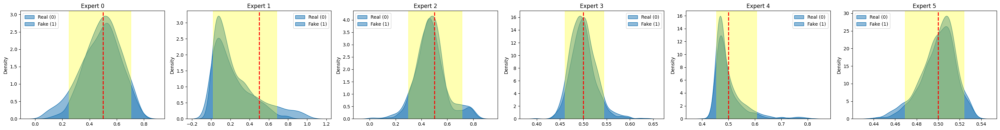


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 54.84%, EER: 47.58%
AUC: 46.37%, EER: 52.71%
AUC: 50.33%, EER: 49.60%
AUC: 56.85%, EER: 44.58%
AUC: 56.37%, EER: 45.98%
AUC: 54.00%, EER: 46.99%


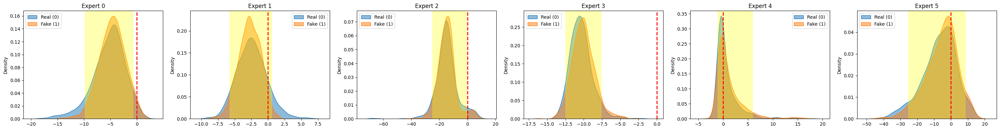


########################################################################################################################
#--------------------------------------------------------- A19 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 67.68%, EER: 39.94%


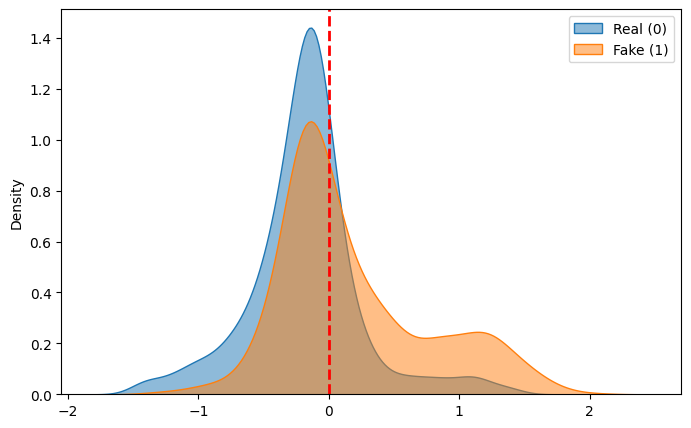


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 64.78%, EER: 39.55%
AUC: 55.37%, EER: 49.27%
AUC: 60.53%, EER: 42.56%
AUC: 60.67%, EER: 42.22%
AUC: 51.32%, EER: 48.85%
AUC: 48.87%, EER: 52.21%


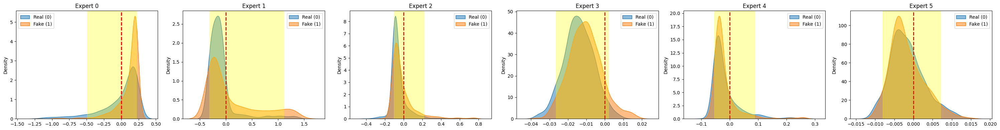


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 65.19%, EER: 39.55%
AUC: 76.37%, EER: 30.18%
AUC: 37.35%, EER: 59.84%
AUC: 39.33%, EER: 57.78%
AUC: 51.32%, EER: 48.85%
AUC: 51.13%, EER: 47.79%


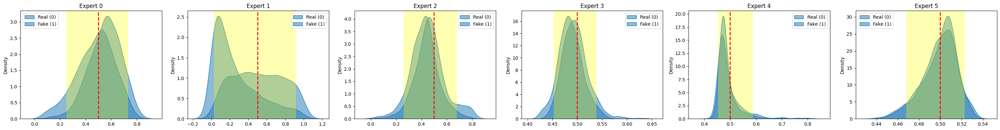


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 65.19%, EER: 39.55%
AUC: 76.37%, EER: 30.18%
AUC: 37.35%, EER: 59.84%
AUC: 39.33%, EER: 57.78%
AUC: 51.32%, EER: 48.85%
AUC: 51.13%, EER: 47.79%


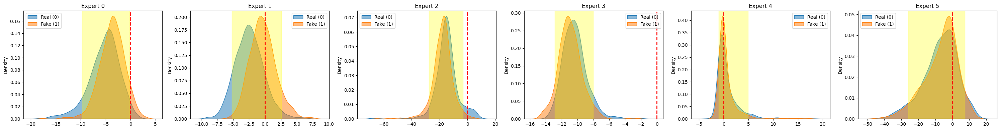


########################################################################################################################
#--------------------------------------------------------- A21 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 59.36%, EER: 40.58%


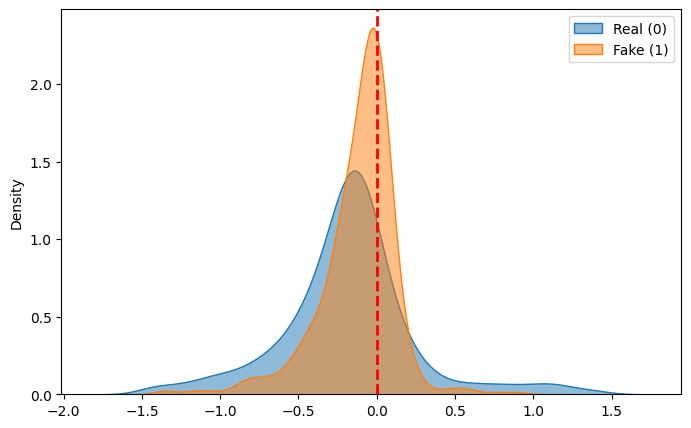


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 57.10%, EER: 46.41%
AUC: 60.90%, EER: 39.75%
AUC: 44.59%, EER: 53.35%
AUC: 35.97%, EER: 59.35%
AUC: 74.18%, EER: 32.65%
AUC: 56.28%, EER: 45.50%


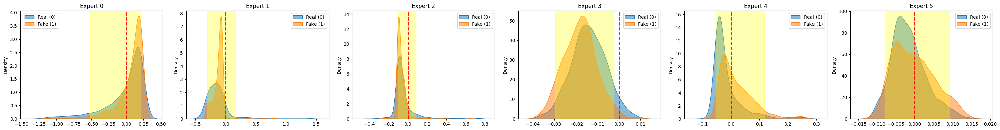


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 56.90%, EER: 46.41%
AUC: 26.83%, EER: 67.97%
AUC: 66.83%, EER: 35.53%
AUC: 64.03%, EER: 40.65%
AUC: 74.18%, EER: 32.65%
AUC: 43.72%, EER: 54.50%


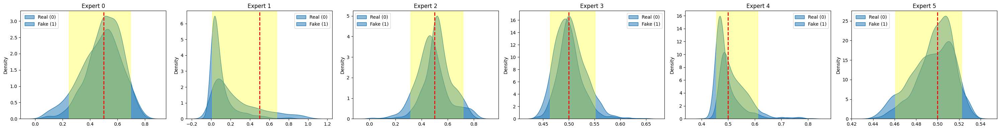


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 56.90%, EER: 46.41%
AUC: 26.83%, EER: 67.97%
AUC: 66.83%, EER: 35.53%
AUC: 64.03%, EER: 40.65%
AUC: 74.18%, EER: 32.65%
AUC: 43.72%, EER: 54.50%


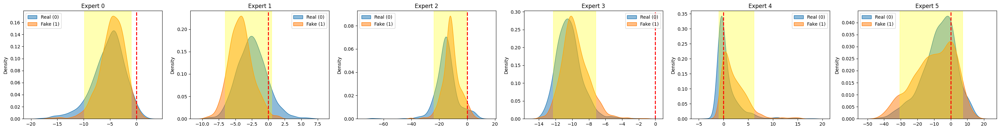


########################################################################################################################
#--------------------------------------------------------- A22 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 55.84%, EER: 45.63%


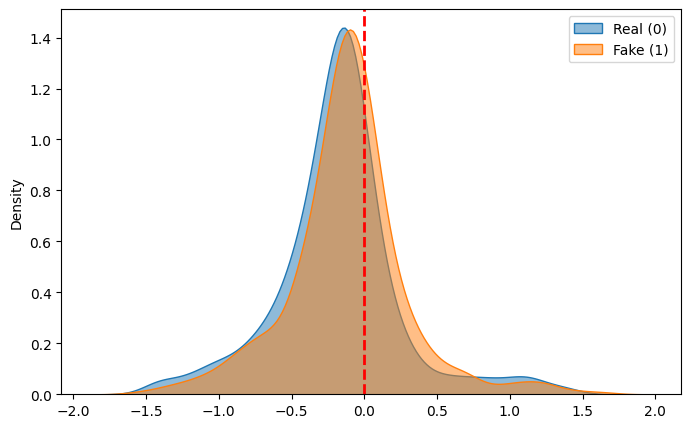


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 51.25%, EER: 48.68%
AUC: 46.76%, EER: 51.80%
AUC: 49.91%, EER: 49.33%
AUC: 32.12%, EER: 63.44%
AUC: 77.31%, EER: 29.07%
AUC: 52.98%, EER: 48.61%


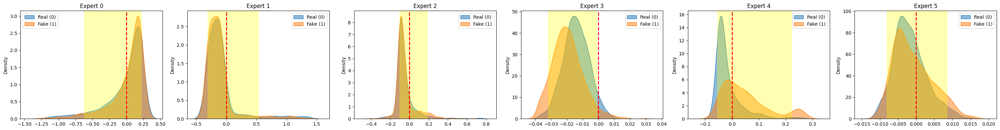


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 51.28%, EER: 48.68%
AUC: 52.10%, EER: 48.61%
AUC: 58.43%, EER: 40.99%
AUC: 67.88%, EER: 36.56%
AUC: 77.31%, EER: 29.07%
AUC: 47.02%, EER: 51.39%


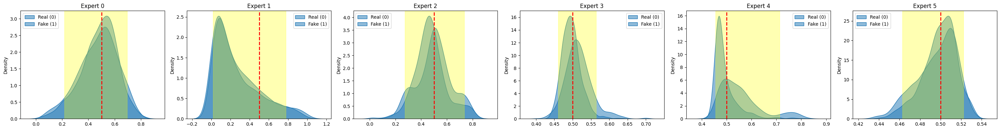


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 51.28%, EER: 48.68%
AUC: 52.10%, EER: 48.61%
AUC: 58.43%, EER: 40.99%
AUC: 67.88%, EER: 36.56%
AUC: 77.31%, EER: 29.07%
AUC: 47.02%, EER: 51.39%


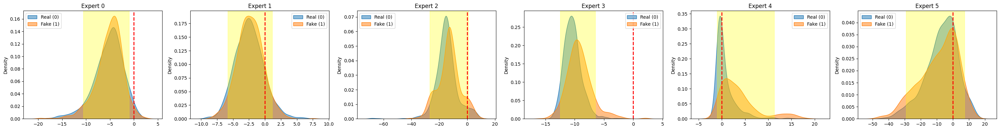


########################################################################################################################
#--------------------------------------------------------- A28 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 53.11%, EER: 49.02%


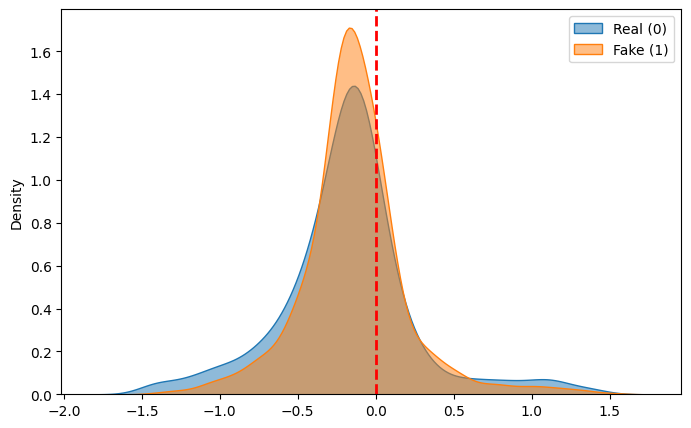


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 54.92%, EER: 47.38%
AUC: 48.07%, EER: 49.95%
AUC: 50.76%, EER: 50.15%
AUC: 39.90%, EER: 56.82%
AUC: 61.28%, EER: 43.90%
AUC: 46.32%, EER: 52.31%


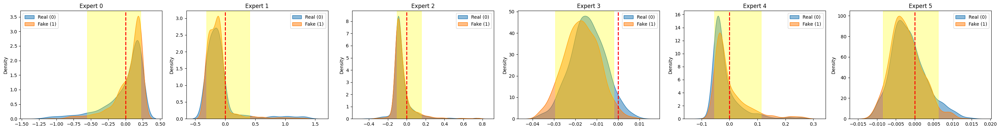


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 54.92%, EER: 47.38%
AUC: 48.55%, EER: 50.67%
AUC: 47.03%, EER: 51.90%
AUC: 60.11%, EER: 43.18%
AUC: 61.28%, EER: 43.90%
AUC: 53.68%, EER: 47.69%


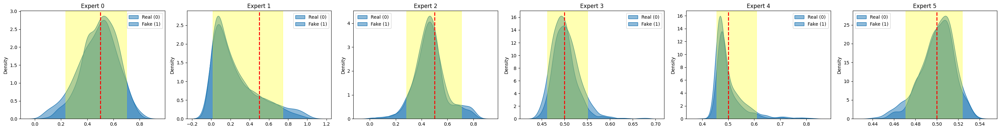


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 54.92%, EER: 47.38%
AUC: 48.55%, EER: 50.67%
AUC: 47.03%, EER: 51.90%
AUC: 60.11%, EER: 43.18%
AUC: 61.28%, EER: 43.90%
AUC: 53.68%, EER: 47.69%


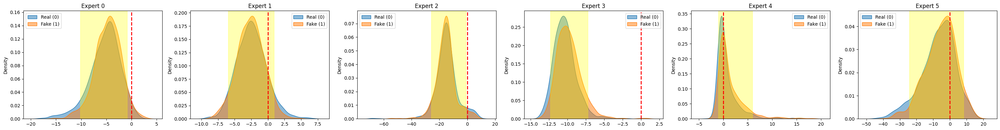


########################################################################################################################
#--------------------------------------------------------- A29 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 48.79%, EER: 51.61%


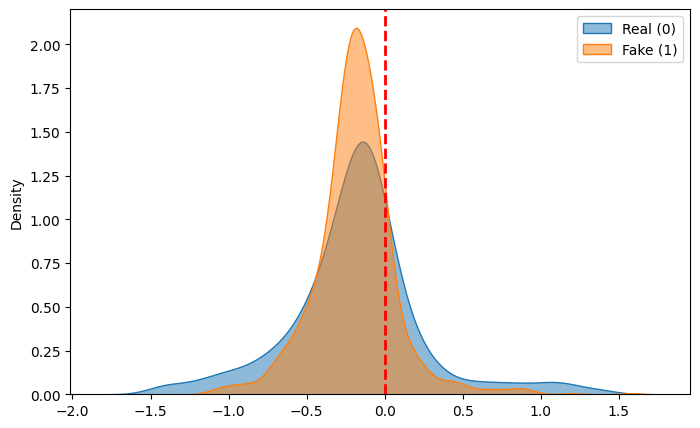


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 57.24%, EER: 46.76%
AUC: 44.39%, EER: 52.75%
AUC: 46.09%, EER: 52.42%
AUC: 30.92%, EER: 63.34%
AUC: 51.07%, EER: 48.92%
AUC: 53.60%, EER: 46.84%


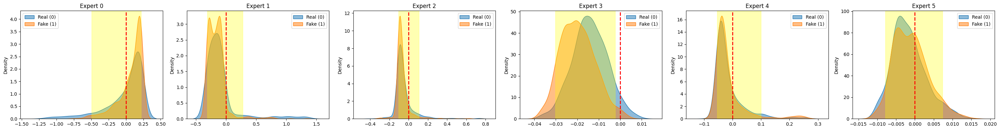


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 57.25%, EER: 46.76%
AUC: 47.54%, EER: 50.77%
AUC: 56.97%, EER: 43.42%
AUC: 69.08%, EER: 36.66%
AUC: 51.07%, EER: 48.92%
AUC: 46.40%, EER: 53.16%


In [ ]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19/6_experts/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            if title == "Scaled Logits":
                thr = 0.5
            else:
                thr = 0

            lbound = np.percentile(scores, 5)
            hbound = np.percentile(scores, 95)

            plot_distributions(scores, labels, lbound, hbound, thr=thr, ax=ax, metrics=True)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()